# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

import cv2

from sklearn.preprocessing import minmax_scale

import torch
from torch.utils.data import DataLoader

from torchvision.datasets import VisionDataset
from torchvision.transforms import v2
from torchvision import tv_tensors

import segmentation_models_pytorch as smp

from torchmetrics import Dice

# Utils & Functions

In [3]:
def set_seed(seed):
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
      torch.cuda.manual_seed(seed)

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [5]:
def segment(image, model):
    with torch.inference_mode():
        prediction = model(image)
        return torch.sigmoid(prediction).cpu()

In [6]:
def dice_calc(model, test_loader):
    model.to(device)
    model.eval()
    with torch.no_grad():
        dice_valid = Dice().to(device)
        for i, (inputs, targets) in enumerate(test_loader):
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
      
            dice_valid(outputs, targets.int())
    return dice_valid.compute().item()

In [7]:
def show_random_results(num, loader, model, model_name):
    img, mask = next(iter(loader))

    output = segment(img.to('cpu'), model)

    for i in range(num):
        plt.figure(figsize=(20,6))
        plt.suptitle(f'Results of {model_name}', fontsize=18)

        plt.subplot(1,3,1)
        plt.title('Input', fontsize=16)
        plt.axis('off')
        plt.imshow(img[i][0], cmap='gray')

        plt.subplot(1,3,2)
        plt.title('Target', fontsize=16)
        handles = [Rectangle((0,0),1,1, color=c) for c in [(1, 0, 0, 0.8), (0, 1, 0, 0.8), (0, 0, 1, 0.8)]]
        labels = ["Stomach", "Large Bowel", "Small Bowel"]
        plt.legend(handles,labels)
        plt.axis('off')
        plt.imshow(img[i][0], cmap='gray')
        plt.imshow(output[i].permute(1, 2, 0), alpha=0.25)

        plt.subplot(1, 3, 3)
        plt.title('Predicted', fontsize=16)
        handles = [Rectangle((0,0),1,1, color=c) for c in [(1, 0, 0, 0.8), (0, 1, 0, 0.8), (0, 0, 1, 0.8)]]
        labels = ["Stomach", "Large Bowel", "Small Bowel"]
        plt.legend(handles,labels)
        plt.axis('off')
        plt.imshow(img[i][0], cmap='gray')
        plt.imshow(mask[i].permute(1, 2, 0).float(), alpha=0.35)

In [8]:
def comapre_results_image(row, set, models, models_name):
    sample, mask = set[row][0].squeeze(), set[row][1]
    handles = [Rectangle((0,0),1,1, color=c) for c in [(1, 0, 0, 0.8), (0, 1, 0, 0.8), (0, 0, 1, 0.8)]]
    labels = ["Stomach", "Large Bowel", "Small Bowel"]
    plt.figure(figsize=(45, 8))
    plt.suptitle(f'Comparison of Results', fontsize=25)
    plt.subplot(1,5,1)
    plt.title('Input', fontsize=22)
    plt.axis('off')
    plt.imshow(sample, cmap='gray')

    plt.subplot(1,5,2)
    plt.title('Target', fontsize=22)
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(sample, cmap='gray')
    plt.imshow(mask.permute(1,2,0), alpha=0.25)


    predict = segment(set[row][0].unsqueeze(0), models[0])
    plt.subplot(1,5,3)
    plt.title(f'{models_name[0]}', fontsize=22)
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(sample, cmap='gray')
    plt.imshow(predict.squeeze().permute(1,2,0), alpha=0.30)

    predict = segment(set[row][0].unsqueeze(0), models[1])
    plt.subplot(1,5,4)
    plt.title(f'{models_name[1]}', fontsize=22)
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(sample, cmap='gray')
    plt.imshow(predict.squeeze().permute(1,2,0), alpha=0.30)

    predict = segment(set[row][0].unsqueeze(0), models[2])
    plt.subplot(1,5,5)
    plt.title(f'{models_name[2]}', fontsize=22)
    plt.legend(handles,labels)
    plt.axis('off')
    plt.imshow(sample, cmap='gray')
    plt.imshow(predict.squeeze().permute(1,2,0), alpha=0.30)

In [9]:
def metrics_calc(model, test_loader, reduction="macro-imagewise"):
    model = model.to(device)
    model.eval()

    tp, fp, fn, tn = [], [], [], []

    dice_valid = Dice().to(device)
    stomach_dice = Dice().to(device)
    large_bowel_dice = Dice().to(device)
    small_bowel_dice = Dice().to(device)

    with torch.inference_mode():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device).int()

            output = torch.sigmoid(model(inputs))

            dice_valid(output, targets)
            stomach_dice(output[:, 0], targets[:, 0])
            large_bowel_dice(output[:, 1], targets[:, 1])
            small_bowel_dice(output[:, 2], targets[:, 2])

            tp_batch, fp_batch, fn_batch, tn_batch = (
                smp.metrics.get_stats((output > 0.5).int(), targets, mode="multilabel", num_classes=3))

            tp.append(tp_batch)
            fp.append(fp_batch)
            fn.append(fn_batch)
            tn.append(tn_batch)

    tp = torch.cat(tp, dim=0)
    fp = torch.cat(fp, dim=0)
    fn = torch.cat(fn, dim=0)
    tn = torch.cat(tn, dim=0)

    iou_score = smp.metrics.iou_score(tp, fp, fn, tn, reduction=reduction).cpu().tolist()

    class_iou_score = smp.metrics.iou_score(tp, fp, fn, tn).mean(dim=0).cpu().tolist()

    f1_score = smp.metrics.f1_score(tp, fp, fn, tn, reduction=reduction).cpu().tolist()

    class_f1_score = smp.metrics.f1_score(tp, fp, fn, tn).mean(dim=0).cpu().tolist()

    recall = smp.metrics.recall(tp, fp, fn, tn, reduction=reduction).cpu().tolist()

    class_recall = smp.metrics.recall(tp, fp, fn, tn).mean(dim=0).cpu().tolist()

    precision = smp.metrics.precision(tp, fp, fn, tn, reduction=reduction).cpu().tolist()

    class_precision = smp.metrics.precision(tp, fp, fn, tn).mean(dim=0).cpu().tolist()

    accuracy = smp.metrics.accuracy(tp, fp, fn, tn, reduction=reduction).cpu().tolist()

    class_accuracy = smp.metrics.accuracy(tp, fp, fn, tn).mean(dim=0).cpu().tolist()

    data = {
        "All": [
            iou_score,
            dice_valid.compute().item(),
            f1_score,
            precision,
            recall,
            accuracy
        ],
        "Stomach": [
            class_iou_score[0],
            stomach_dice.compute().item(),
            class_f1_score[0],
            class_precision[0],
            class_recall[0],
            class_accuracy[0]
        ],
        "Large Bowel": [
            class_iou_score[1],
            large_bowel_dice.compute().item(),
            class_f1_score[1],
            class_precision[1],
            class_recall[1],
            class_accuracy[1]
        ],
        "Small Bowel": [
            class_iou_score[2],
            small_bowel_dice.compute().item(),
            class_f1_score[2],
            class_precision[2],
            class_recall[2],
            class_accuracy[2]
        ]
    }

    return pd.DataFrame(data, index=["IOU", "Dice", "F1 Score", "Precision", "Recall", "Accuracy"])

In [10]:
def plot_metrics(metric):
    plt.figure(figsize=(18, 8))
    metric_data = df_melted[df_melted['Metric'] == metric]
    sns.barplot(x='Class', y='Score', hue='Model', data=metric_data, palette='muted')
    plt.title(f'{metric} Comparison Across Models and Classes')
    plt.xlabel('Class')
    plt.ylabel(f'{metric} Score')
    plt.legend(title='Model')
    plt.show()

In [11]:
def plot_metrics(metric, ax):
    sns.boxplot(x='Model', y='Score', hue='Class', data=df_melted[df_melted['Metric'] == metric], ax=ax)
    ax.set_title(f'{metric} by Model and Class')
    ax.set_ylabel('Score')
    ax.set_xlabel('Model')
    ax.legend(loc='best')

In [12]:
def rle2mask(rle, shape):
    rle_list = rle.split(' ')
    rle_list = np.array(rle_list, dtype=np.uint32)
    starts = rle_list[::2] - 1
    lengths = rle_list[1::2]
    mask = np.zeros(shape[0] * shape[1])
    for s,l in zip(starts,lengths):
        mask[s:s+l] = 1
    return mask.reshape(shape)


def masks(df, row, sample):
    masks = np.zeros((3, sample.shape[0], sample.shape[1]))
    if pd.notna(df.iloc[row]['stomach']):
        masks[0, :, :] = rle2mask(df.iloc[row]['stomach'], sample.shape)
    
    if pd.notna(df.iloc[row]['large_bowel']):
        masks[1, :, :] = rle2mask(df.iloc[row]['large_bowel'], sample.shape)
    
    if pd.notna(df.iloc[row]['small_bowel']):
        masks[2, :, :] = rle2mask(df.iloc[row]['small_bowel'], sample.shape)
    
    return masks

# Loading Data & Models

In [13]:
class ImageDataset(VisionDataset):
    def __init__(self, dataframe, transforms=None, memory=False):
        super().__init__(transforms=transforms)
        self.df = dataframe
        self.df['path'] = self.df['path'].astype(str).apply(lambda p: p if p.startswith('./data/') else './data/' + p)
        self.classes = ['Stomach', 'Large Bowel', 'Small Bowel']
        self.memory = memory
        if memory:
            self.save_memory()

    def __getitem__(self, row):
        img = self.imgs[row] if self.memory else cv2.imread(self.df.iloc[row]['path'], cv2.IMREAD_UNCHANGED).astype(np.float32)
        img = img.squeeze()
        #img = cv2.imread(self.df.iloc[row]['path'], cv2.IMREAD_UNCHANGED).astype(np.float32)
        mask = masks(self.df, row, img)
        img = tv_tensors.Image(img)
        mask = tv_tensors.Mask(mask)
        img, mask = self.transforms(img, mask)
        return img, mask
        
    def __len__(self):
        return self.df.shape[0]

    def save_memory(self):
        self.imgs = []
        for path in self.df['path']:
            img = cv2.imread(path, cv2.IMREAD_UNCHANGED).astype(np.float32)
            img = tv_tensors.Image(minmax_scale(img))
            self.imgs.append(img)

In [14]:
test_transform = v2.Compose([
    v2.Resize(size=(224, 224)),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min())),
    v2.Normalize(mean=(0.5,), std=(0.5,))
    ])

In [15]:
test_df = pd.read_csv('./splits_data/test_df.csv')
test_set = ImageDataset(test_df, transforms=test_transform, memory=True)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)
random_test_loader = DataLoader(test_set, batch_size=32, shuffle=True)
print(test_loader.dataset.df.shape)

(3067, 10)


In [16]:
unet = torch.load('./models/Unet(Resnet34).pt').to('cpu')
unetpp = torch.load('./models/UnetPlusPlus(Resnet34).pt').to('cpu')
deeplabv3p = torch.load('./models/DeepLabv3P(Resnet34).pt').to('cpu')
models = [unet, unetpp, deeplabv3p]
model_names = ['Unet', 'Unet++', 'DeepLabV3+']

# UNet Results

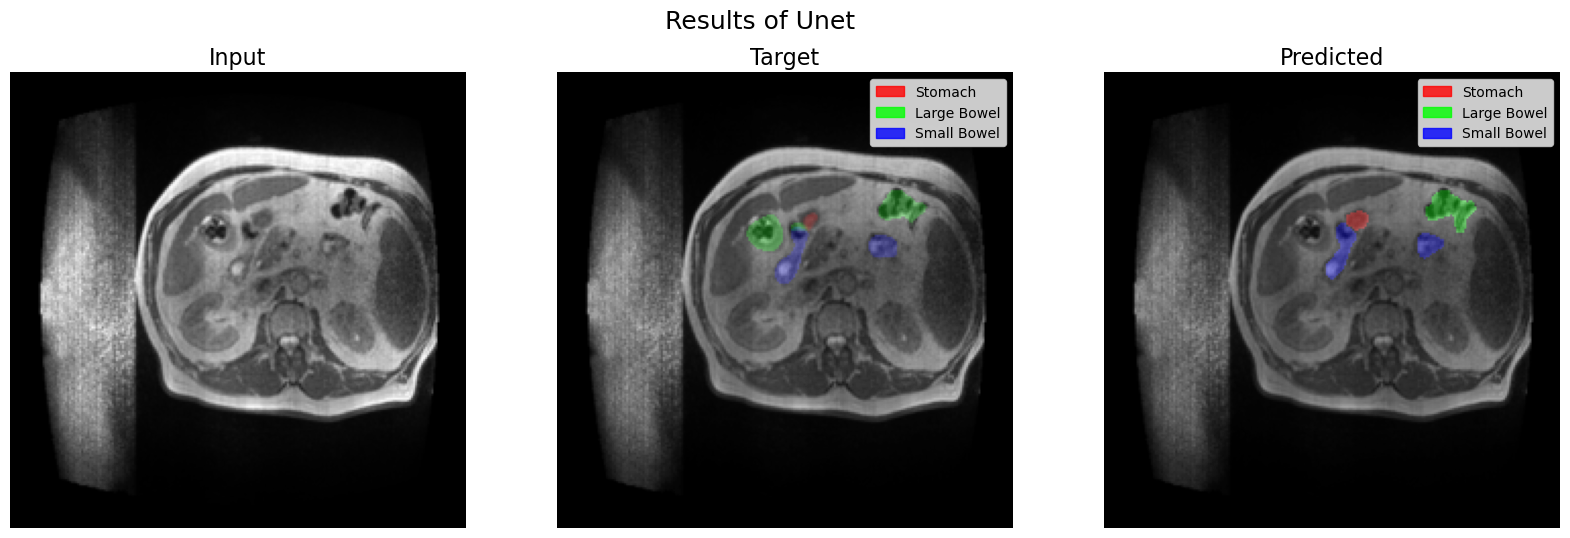

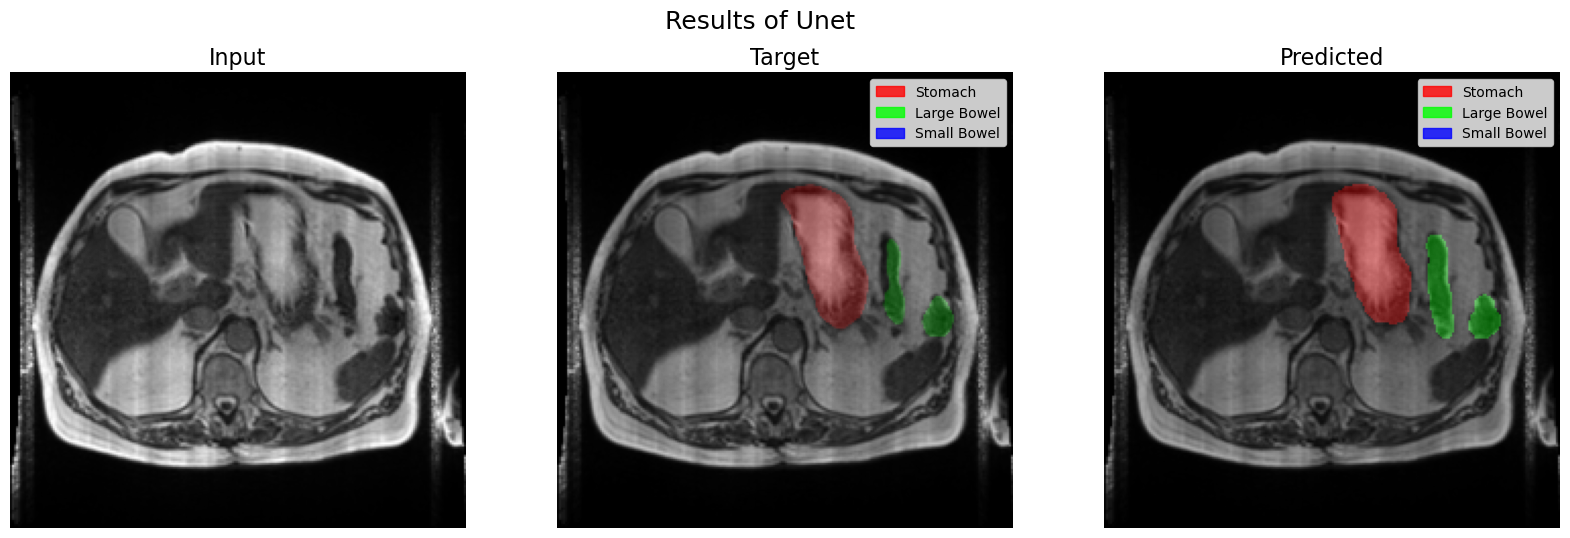

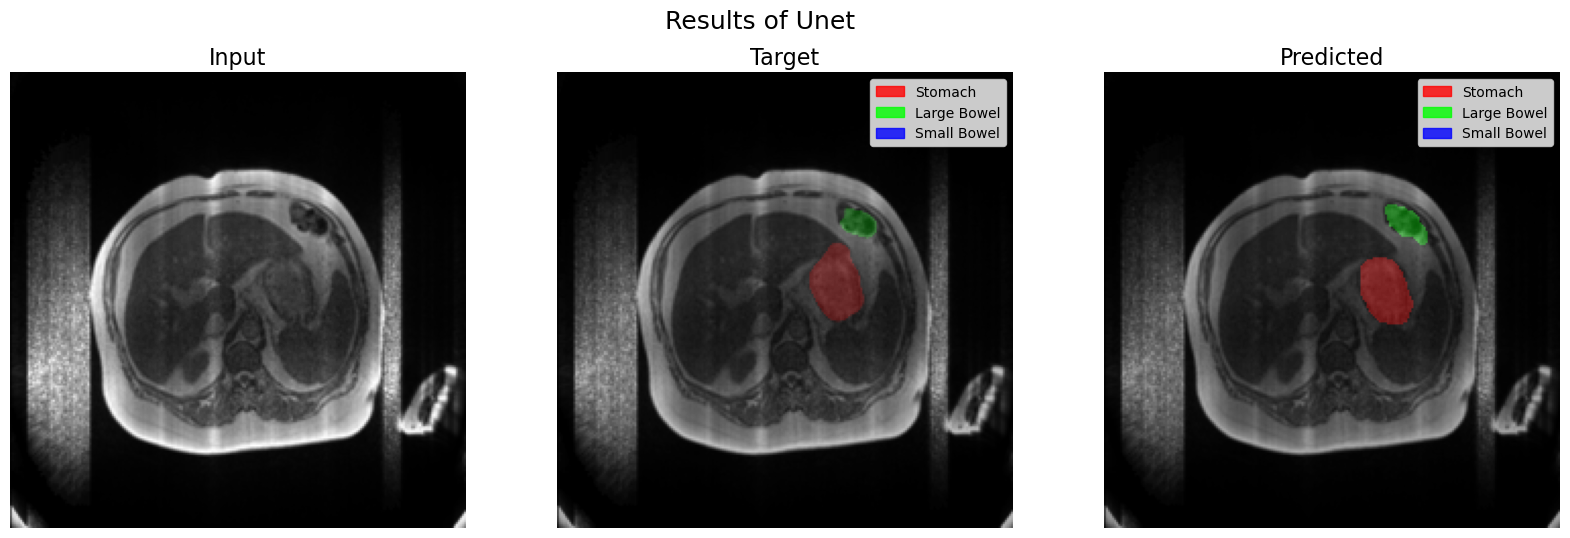

In [18]:
show_random_results(3, random_test_loader, models[0], model_names[0])

# UNet++ Results

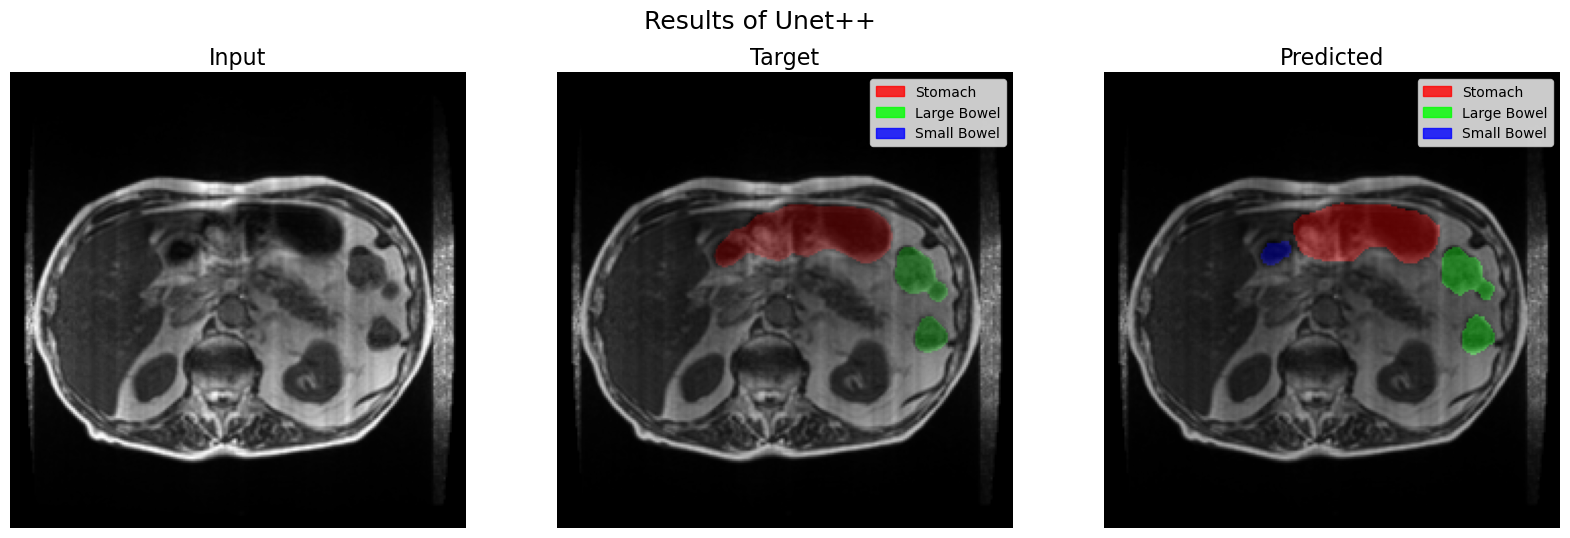

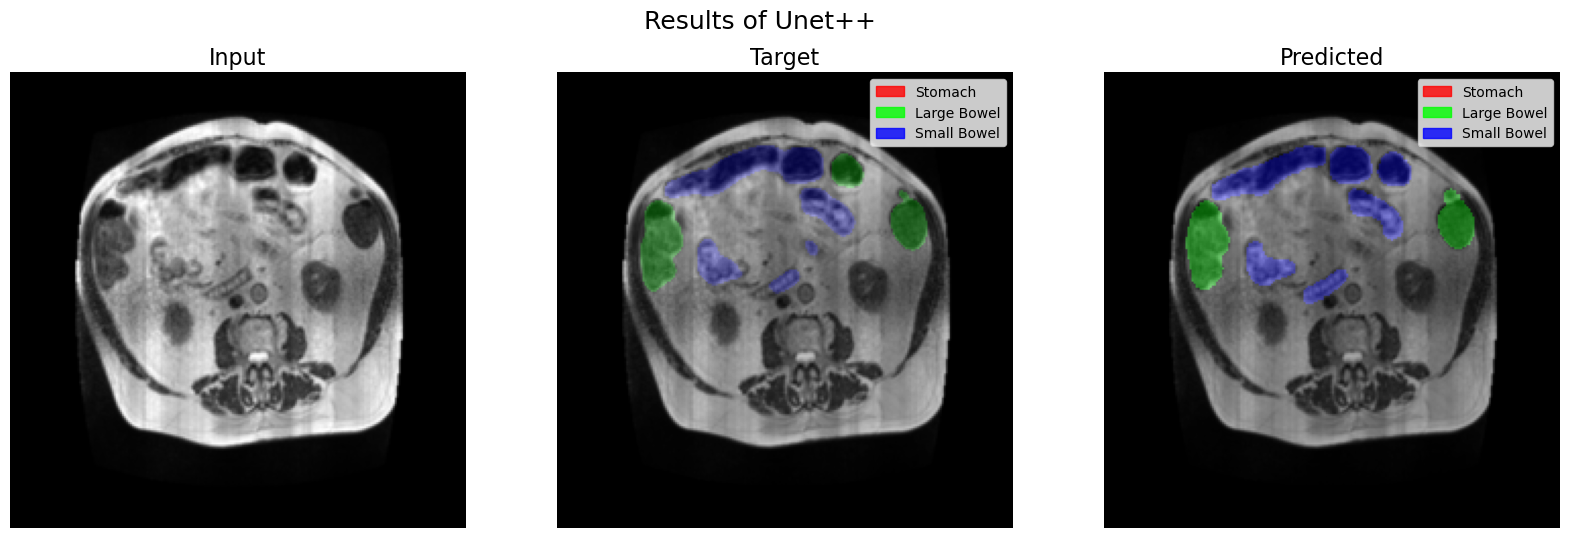

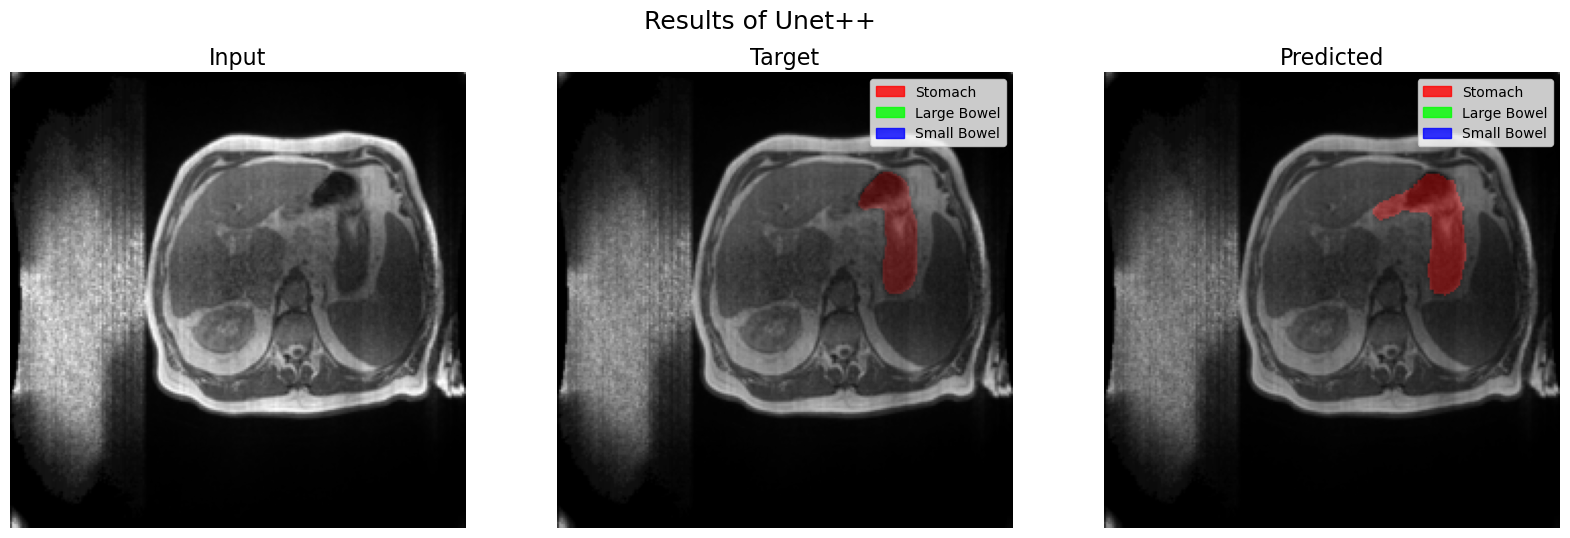

In [19]:
show_random_results(3, random_test_loader, models[1], model_names[1])

# DeepLabV3+ Results 

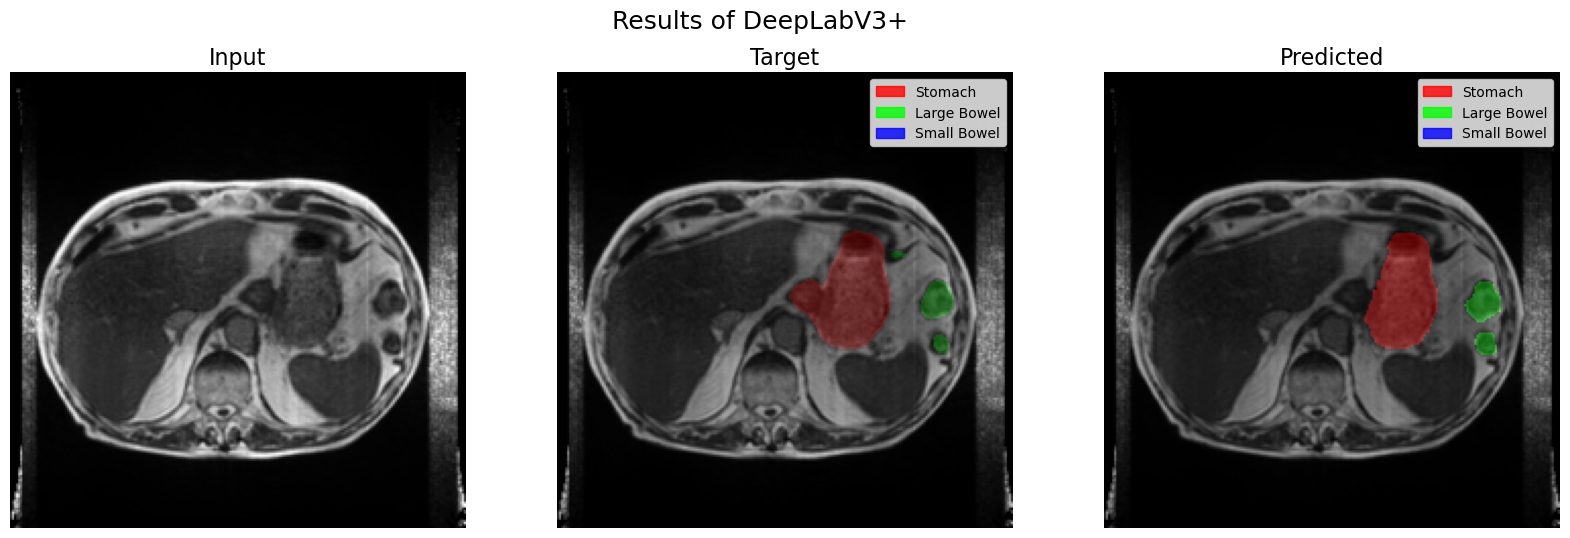

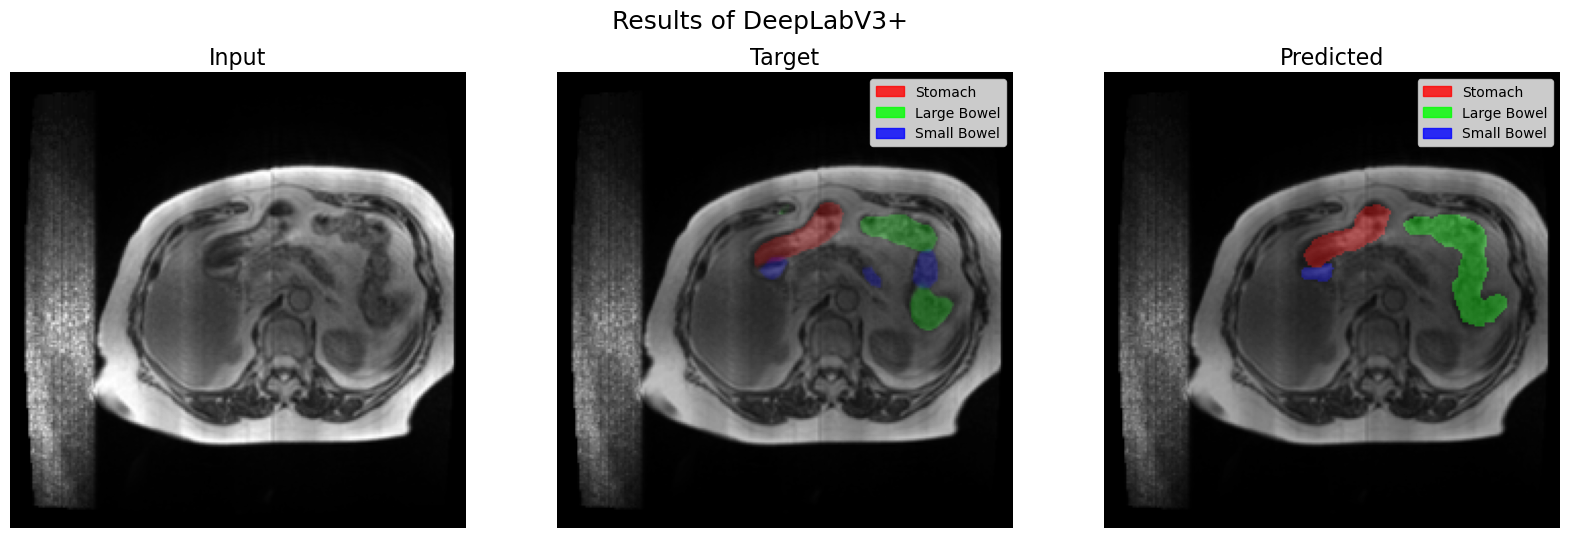

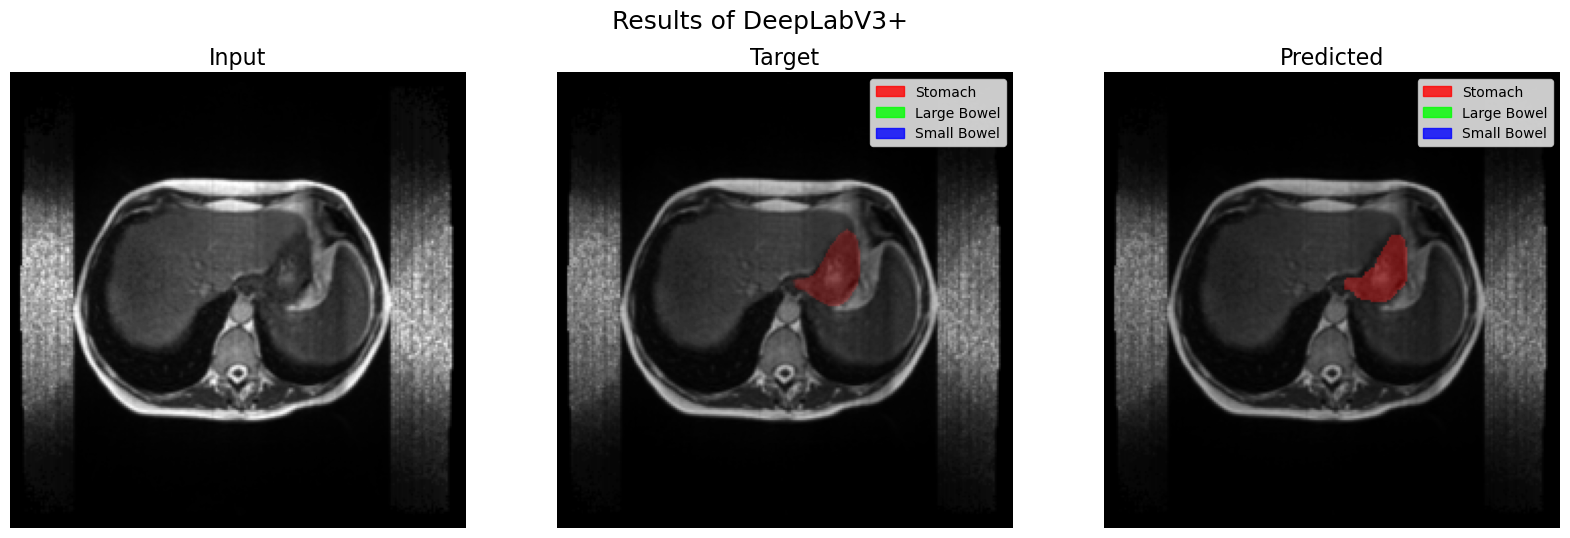

In [25]:
show_random_results(3, random_test_loader, models[2], model_names[2])

# Comparison

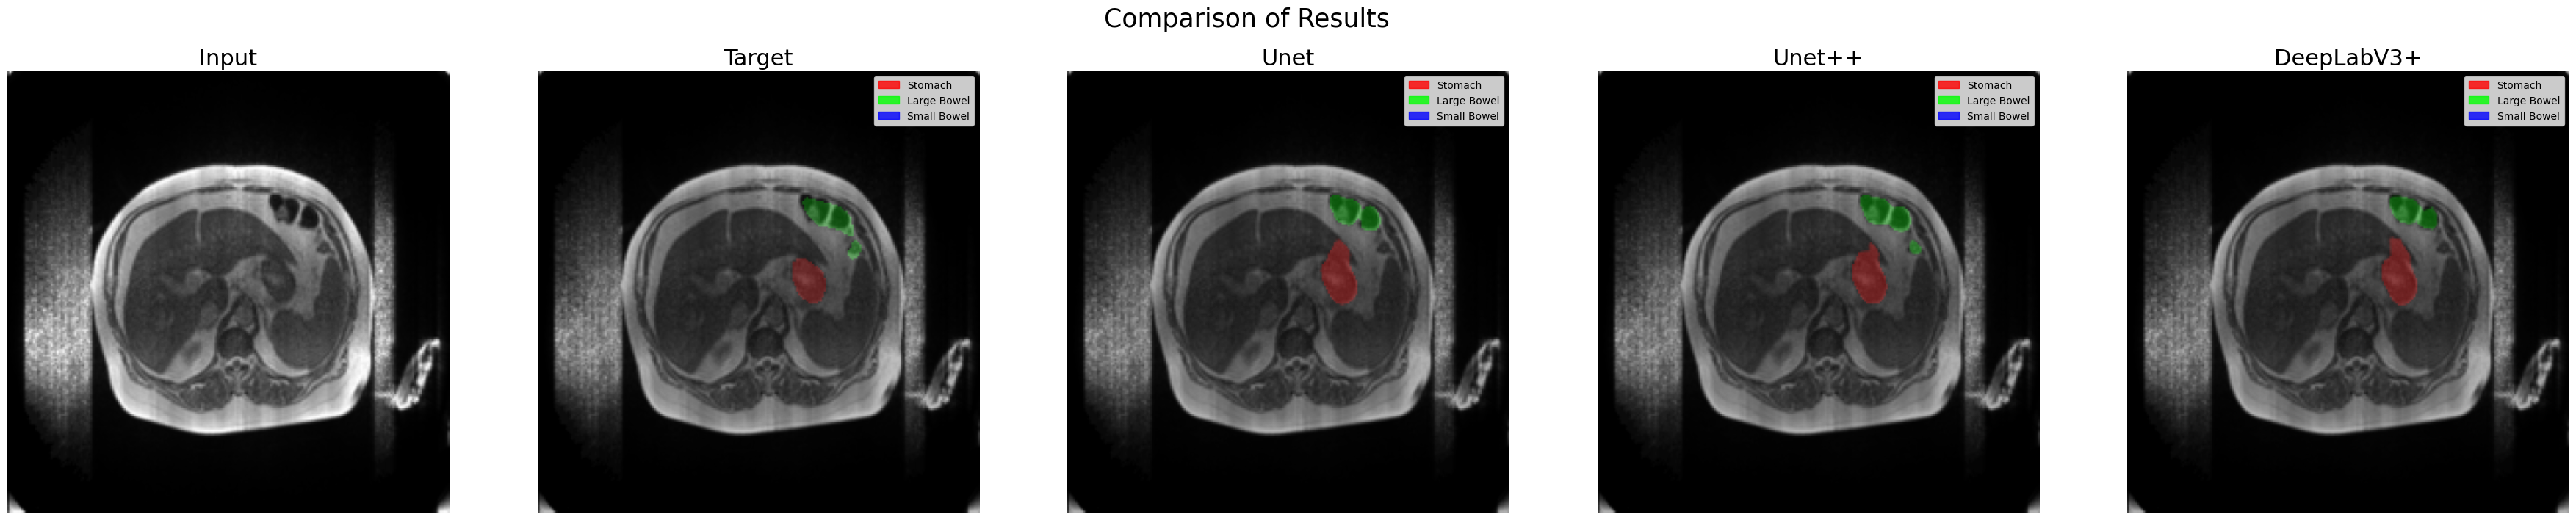

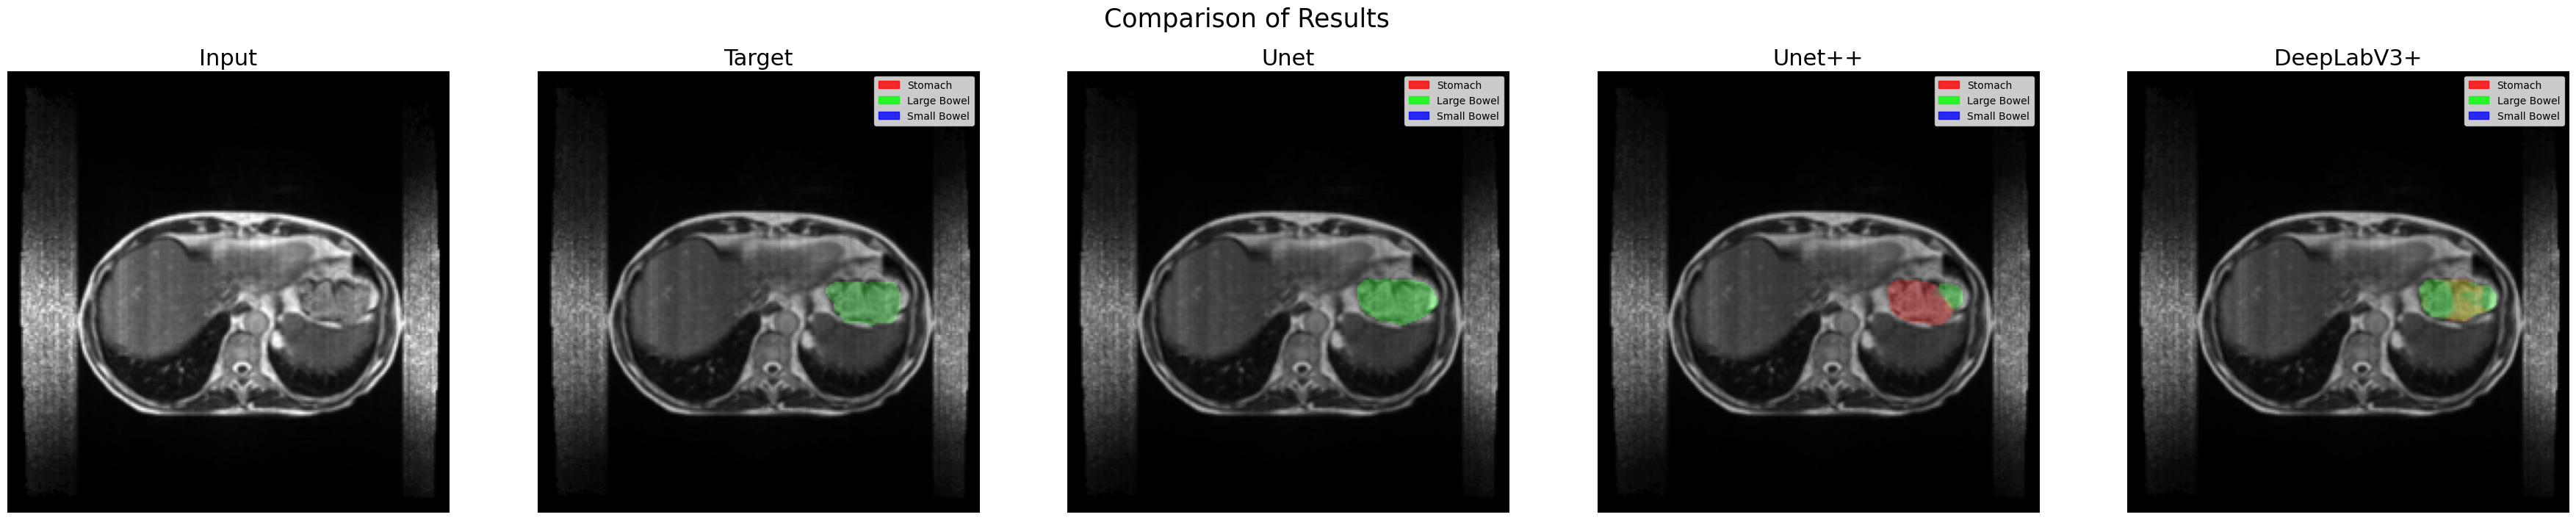

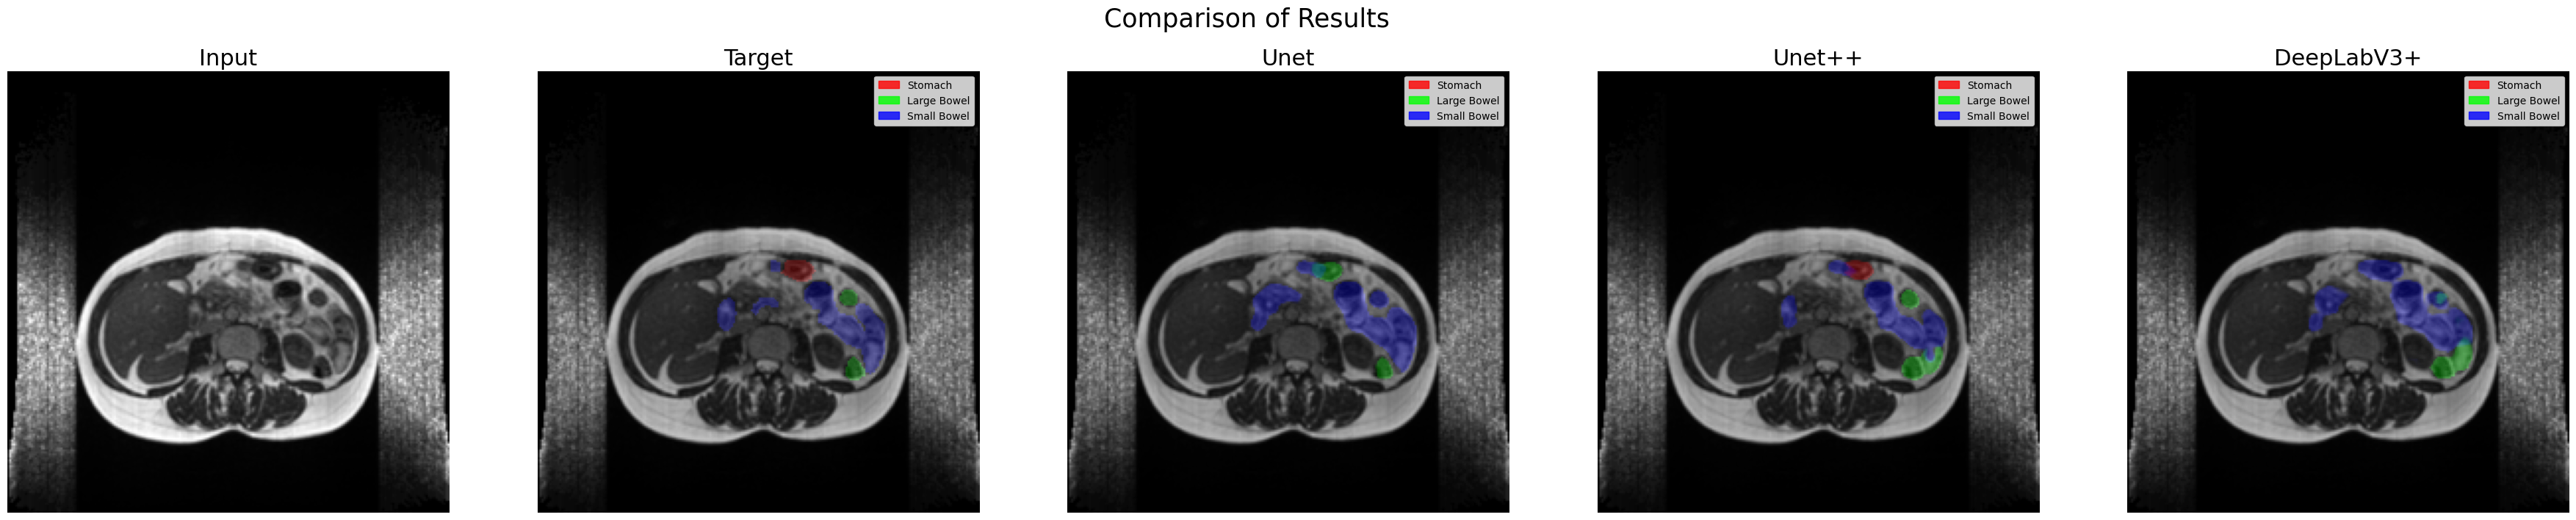

In [30]:
for i in range(3):
    rand_num = np.random.randint(0, len(test_set))
    comapre_results_image(rand_num, test_set, models, model_names)

# Evaluation Metrics

In [31]:
dice_unet = dice_calc(models[0], test_loader)
print(f'Dice {model_names[0]} : {dice_unet}')
dice_unetpp = dice_calc(models[1], test_loader)
print(f'Dice {model_names[1]} : {dice_unetpp}')
dice_deeplab = dice_calc(models[2], test_loader)
print(f'Dice {model_names[2]} : {dice_deeplab}')

Dice Unet : 0.803178071975708
Dice Unet++ : 0.8023282885551453
Dice DeepLabV3+ : 0.7822930216789246


In [32]:
unet_results = metrics_calc(models[0], test_loader)
unet_results

,All,Stomach,Large Bowel,Small Bowel
IOU,0.728016,0.800922,0.698758,0.684368
Dice,0.803158,0.871647,0.823175,0.734358
F1 Score,0.801427,0.847221,0.788416,0.768644
Precision,0.834946,0.894707,0.821944,0.788186
Recall,0.843035,0.880567,0.825578,0.822959
Accuracy,0.994951,0.997673,0.994414,0.992764


In [33]:
unetplusplus_results = metrics_calc(models[1], test_loader)
unetplusplus_results

,All,Stomach,Large Bowel,Small Bowel
IOU,0.730322,0.812733,0.692249,0.685983
Dice,0.802347,0.867663,0.817924,0.739098
F1 Score,0.803184,0.859249,0.781016,0.769287
Precision,0.838164,0.902173,0.815702,0.796616
Recall,0.842461,0.884895,0.822943,0.819546
Accuracy,0.994963,0.997604,0.994209,0.993077


In [34]:
deeplabv3_results = metrics_calc(models[2], test_loader)
deeplabv3_results

,All,Stomach,Large Bowel,Small Bowel
IOU,0.704546,0.783611,0.671865,0.658161
Dice,0.782665,0.854083,0.807360,0.707856
F1 Score,0.782003,0.833389,0.766453,0.746168
Precision,0.820370,0.883939,0.816157,0.761013
Recall,0.827349,0.869632,0.798675,0.813739
Accuracy,0.994477,0.997393,0.994017,0.992021


In [35]:
unet_results.to_csv('./results/unet_results.csv', index=True)
unetplusplus_results.to_csv('./results/unetplusplus_results.csv', index=True)
deeplabv3_results.to_csv('./results/deeplabv3p_results.csv', index=True)

In [36]:
unet_results = pd.read_csv('./results/unet_results.csv', index_col=0)
unetplusplus_results = pd.read_csv('./results/unetplusplus_results.csv', index_col=0)
deeplabv3_results = pd.read_csv('./results/deeplabv3p_results.csv', index_col=0)

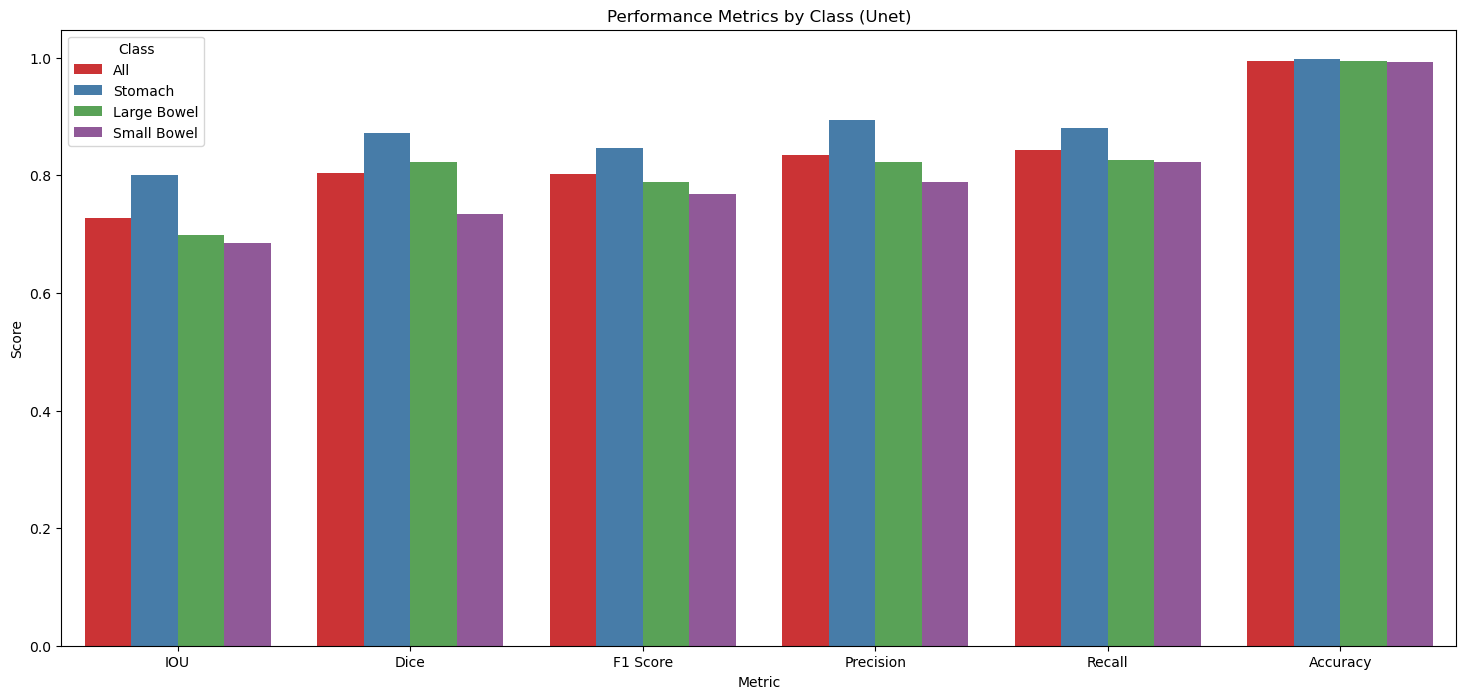

In [37]:
unet_melted = unet_results.reset_index().melt(id_vars='index', var_name='Class', value_name='Score')

unet_melted.columns = ['Metric', 'Class', 'Score']

plt.figure(figsize=(18, 8))

sns.barplot(x='Metric', y='Score', hue='Class', data=unet_melted, palette='Set1')
plt.title('Performance Metrics by Class (Unet)')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.show()


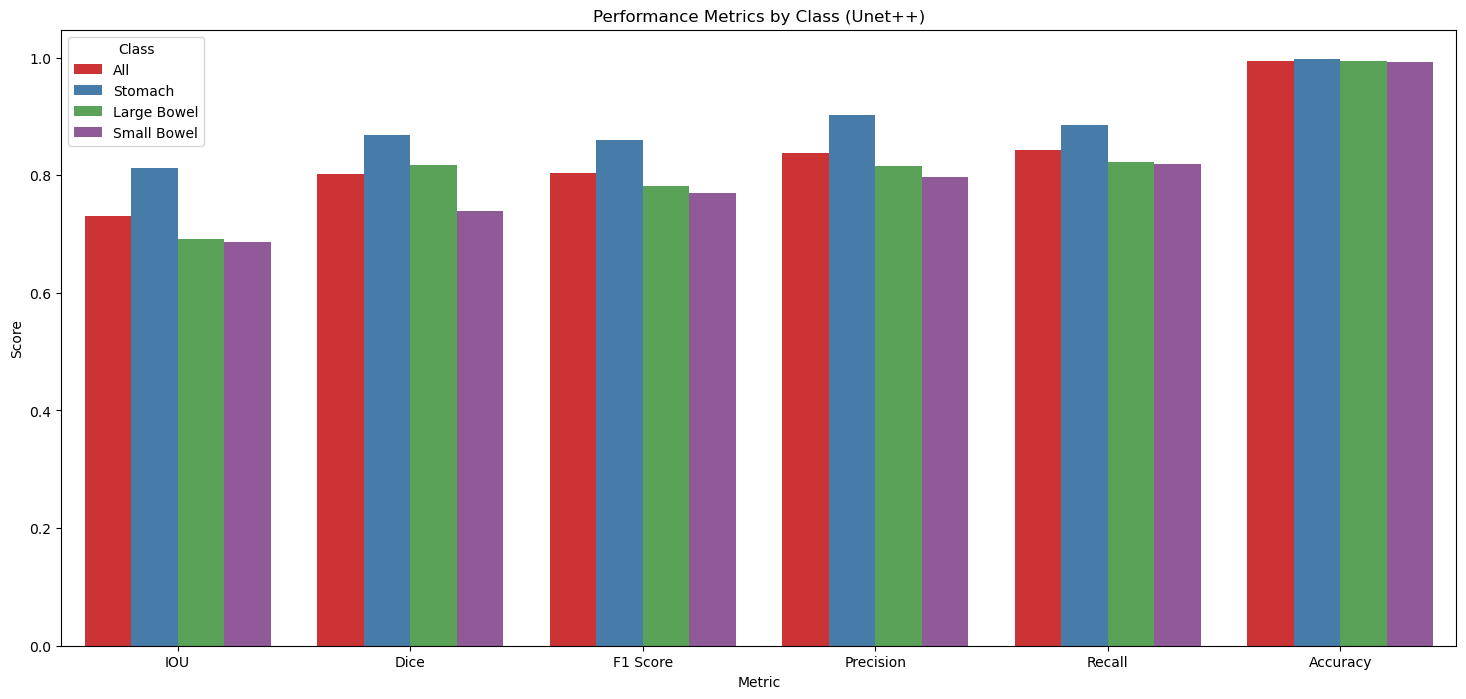

In [38]:
unetpp_melted = unetplusplus_results.reset_index().melt(id_vars='index', var_name='Class', value_name='Score')

unetpp_melted.columns = ['Metric', 'Class', 'Score']

plt.figure(figsize=(18, 8))

sns.barplot(x='Metric', y='Score', hue='Class', data=unetpp_melted, palette='Set1')
plt.title('Performance Metrics by Class (Unet++)')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.show()


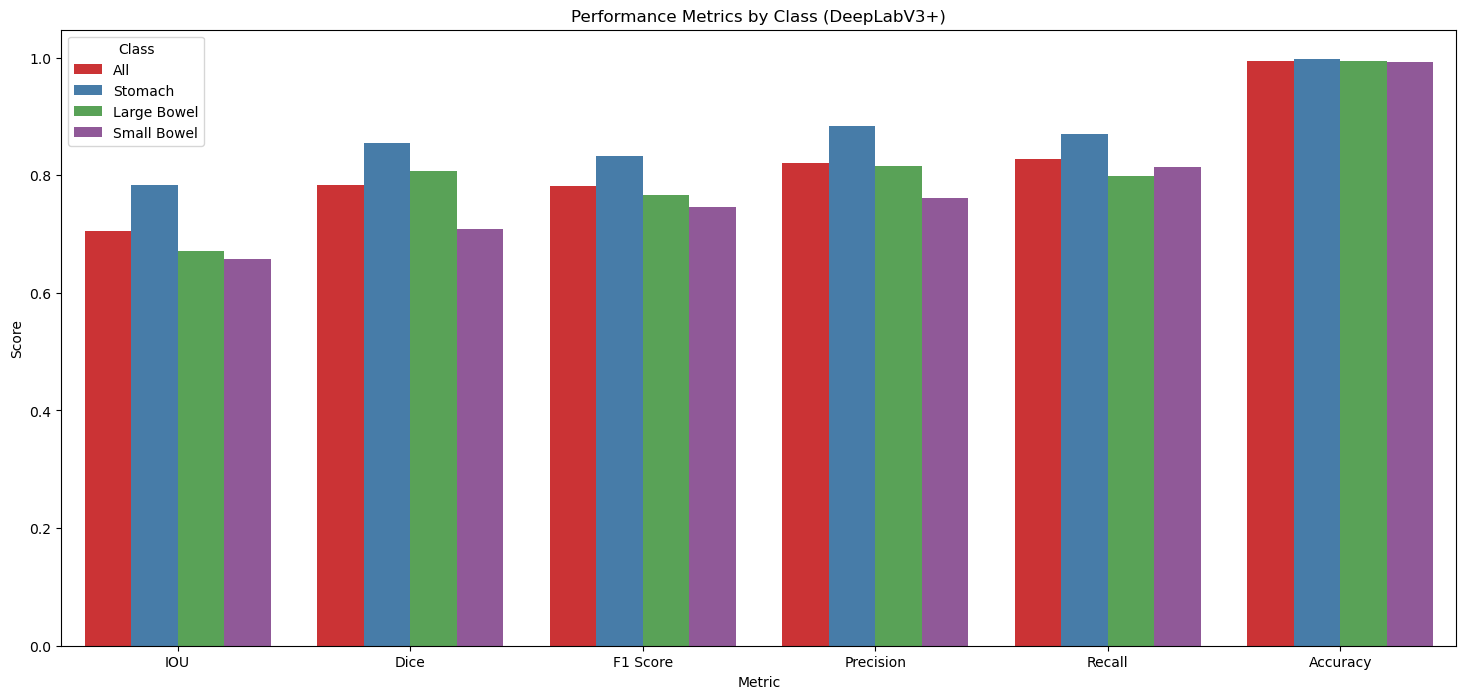

In [39]:
dlv3_melted = deeplabv3_results.reset_index().melt(id_vars='index', var_name='Class', value_name='Score')

dlv3_melted.columns = ['Metric', 'Class', 'Score']

plt.figure(figsize=(18, 8))

sns.barplot(x='Metric', y='Score', hue='Class', data=dlv3_melted, palette='Set1')
plt.title('Performance Metrics by Class (DeepLabV3+)')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.show()


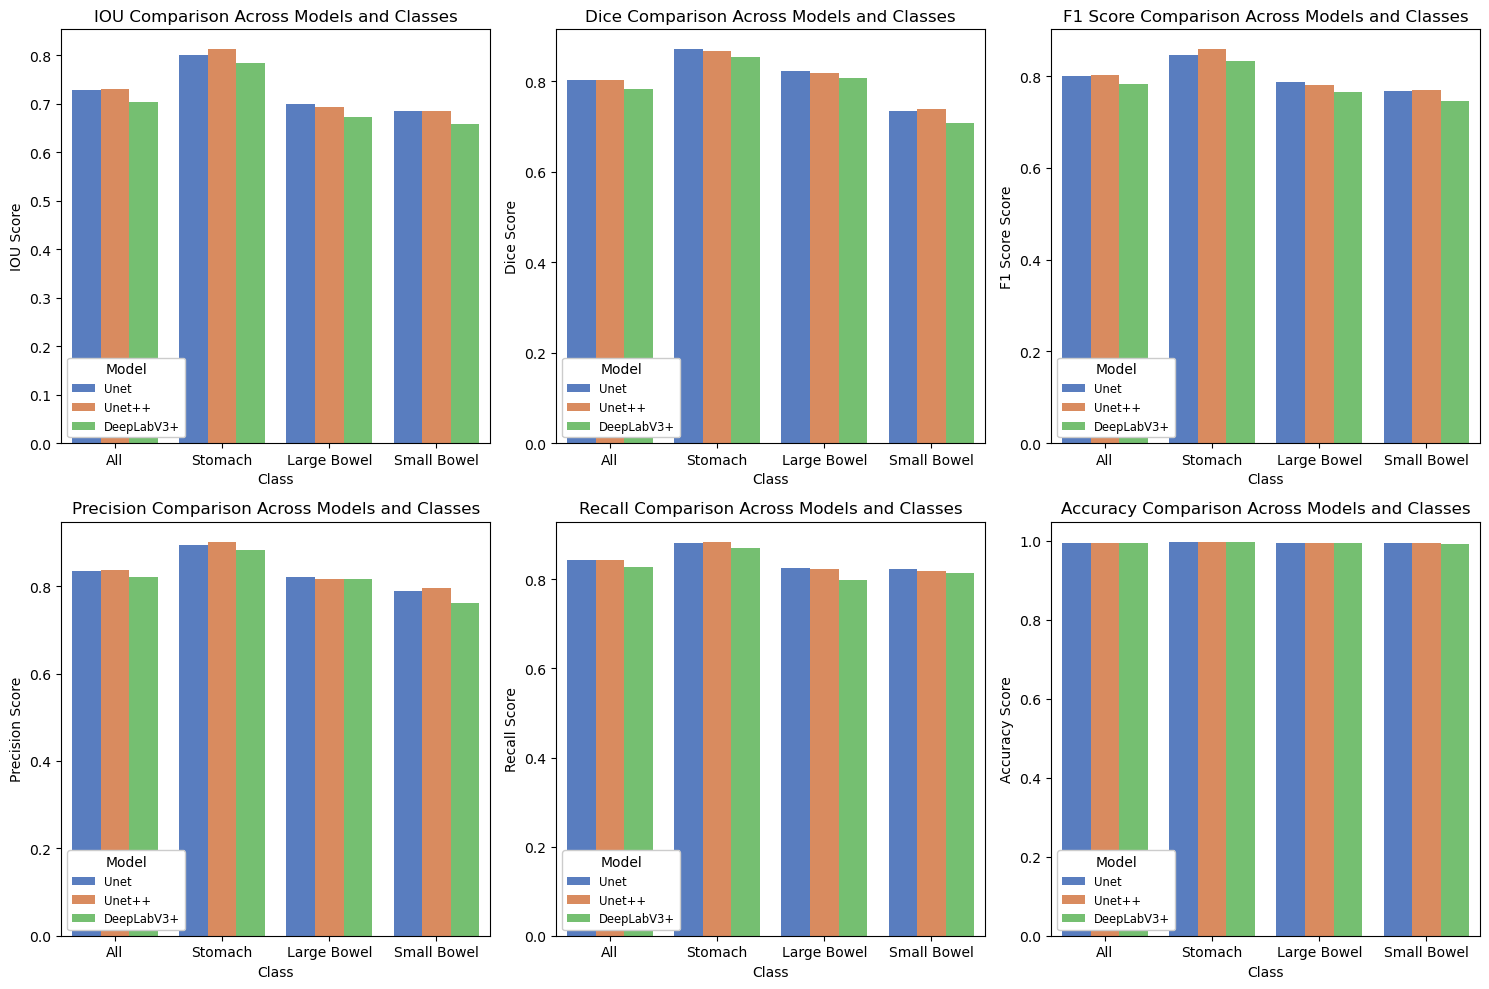

In [40]:
unet_results['Model'] = 'Unet'
unetplusplus_results['Model'] = 'Unet++'
deeplabv3_results['Model'] = 'DeepLabV3+'

df_combined = pd.concat([unet_results, unetplusplus_results, deeplabv3_results])

df_melted = df_combined.reset_index().melt(id_vars=['index', 'Model'], var_name='Class', value_name='Score')
df_melted.columns = ['Metric', 'Model', 'Class', 'Score']

metrics = ["IOU", "Dice", "F1 Score", "Precision", "Recall", "Accuracy"]

def plot_metrics(metric, ax):
    metric_data = df_melted[df_melted['Metric'] == metric]
    sns.barplot(x='Class', y='Score', hue='Model', data=metric_data, palette='muted', ax=ax)
    ax.set_title(f'{metric} Comparison Across Models and Classes')
    ax.set_xlabel('Class')
    ax.set_ylabel(f'{metric} Score')
    legend = ax.legend(title='Model', loc='lower left',  fontsize='small')
    legend.get_frame().set_alpha(1)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for i, metric in enumerate(metrics):
    plot_metrics(metric, axes[i])

plt.tight_layout()
plt.show()
